In [2]:
from random import random

import numpy as np
import os
import torch
import utils
from utils import *
from unet import ImCondModel, UNetModel_imcond_wrapper
from topodataset import TopoDataSet
from tqdm import tqdm
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
weight_path = '../model_weights/otcfm_topo_weights_step_145000.pt'

In [4]:
# load the data:
# DATASETS/DATALOADER
bs=4
num_workers=4
downsampling_factor=1
limit_num_data=np.inf
crop_size=300
use_cfg=True
use_ddc=False
threshold_input=True


dataset = TopoDataSet(
    dir='../data/',
    downsampling_factor=downsampling_factor,
    limit_num_data=limit_num_data,
    crop_size=crop_size,
    threshold_input=threshold_input,
)

dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=bs,
    shuffle=True,
    num_workers=num_workers,
    drop_last=True,
)

dataset contains 8678 images


In [5]:
# get images from training set:
all_imgs = []
all_bgs = []
for i, (img, bg) in tqdm(enumerate(dataloader), total=len(dataloader)):
    all_imgs.append(img)
    all_bgs.append(bg)
    if i >= 100:
        break


  5%|▍         | 100/2169 [00:16<05:41,  6.06it/s]


In [6]:
all_imgs = torch.cat(all_imgs, dim=0)
all_bgs = torch.cat(all_bgs, dim=0)
all_imgs *= 0.5
all_imgs += 0.5

In [7]:
print(all_imgs.shape)

torch.Size([404, 3, 300, 300])


In [8]:


# Load the model
h = w = 300
num_channel = 32
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)


num_im_cond_channels = 1
if use_cfg:
    num_im_cond_channels  += 1
if use_ddc:
    num_im_cond_channels += 3  # 3 as the cell staining images have 3 channels
model = UNetModel_imcond_wrapper(
    dim=(3, h, w),
    num_res_blocks=2,
    num_channels=num_channel,
    channel_mult=[1, 1, 2, 2, 2],
    num_heads=4,
    num_head_channels=-1,
    attention_ds=(2**5,),
    dropout=0.1,
    num_cond_im_channels=num_im_cond_channels,
).to(device)
    


cuda
using model with image conditioning injection in unet!


D:\topochip-flow-matching\Topochip-flow-matching\venv\Lib\site-packages\torch\nn\init.py:453: UserWarning: Initializing zero-element tensors is a no-op
  warnings.warn("Initializing zero-element tensors is a no-op")


In [9]:
checkpoint = torch.load(weight_path, map_location=device)

C:\Users\s161975\AppData\Local\Temp\ipykernel_9428\2211059199.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(weight_path, map_location=device)


In [10]:
device

'cuda'

In [11]:
key = 'ema_model'  # or 'net_model'
# key = 'net_model'
model.load_state_dict(checkpoint[key])

<All keys matched successfully>

In [12]:
model.to(device)

UNetModel_imcond_wrapper(
  (time_embed): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
  )
  (input_blocks): ModuleList(
    (0): TimestepEmbedSequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
    (1-2): 2 x TimestepEmbedSequential(
      (0): ResBlock(
        (in_layers): Sequential(
          (0): GroupNorm32(32, 32, eps=1e-05, affine=True)
          (1): SiLU()
          (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        )
        (h_upd): Identity()
        (x_upd): Identity()
        (emb_layers): Sequential(
          (0): SiLU()
          (1): Linear(in_features=128, out_features=32, bias=True)
        )
        (imcond_emb_layers): Sequential(
          (0): SiLU()
          (1): LazyConv2d(0, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        )
        (out_layers): Sequential(
          (

In [13]:
# generate k qualtitative images of real and fake data:

k = 20
bs = 4

imgs_gen = []
imgs_real = []
for i in tqdm(range(np.ceil(k/bs).astype(int))):
    random_idx = np.random.randint(all_bgs.shape[0], size=bs)
    x1 = all_imgs[random_idx].to(device)
    bg = all_bgs[random_idx].to(device)
    some_bgs = utils.prepare_cfg_conditioning(bg, 0) if use_cfg else bg
    imgs_this_gen = generate_samples_topo(model, None, 0, 'test', some_bgs[:, None, ...], num_int_steps=100,
                                          use_cfg=True, cfg_strength=1, x1=x1)
    imgs_gen.append(imgs_this_gen.cpu())
    img_and_bg_real = torch.cat([all_bgs[random_idx], all_imgs[random_idx]], dim=1)
    imgs_real.append(img_and_bg_real.cpu())

imgs_gen = torch.cat(imgs_gen, dim=0)
imgs_real = torch.cat(imgs_real, dim=0)



  0%|          | 0/5 [00:00<?, ?it/s]

Your vector field does not have `nn.Parameters` to optimize.


 20%|██        | 1/5 [00:36<02:26, 36.68s/it]

Your vector field does not have `nn.Parameters` to optimize.


 40%|████      | 2/5 [01:12<01:48, 36.12s/it]

Your vector field does not have `nn.Parameters` to optimize.


 60%|██████    | 3/5 [01:52<01:16, 38.05s/it]

Your vector field does not have `nn.Parameters` to optimize.


 80%|████████  | 4/5 [02:28<00:37, 37.06s/it]

Your vector field does not have `nn.Parameters` to optimize.


100%|██████████| 5/5 [03:03<00:00, 36.79s/it]


C:\Users\s161975\AppData\Local\Temp\ipykernel_9428\3280891702.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(w_pad=1.08, h_pad=3.08)


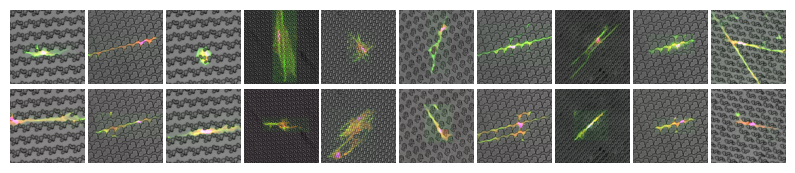

In [14]:
js = [0,1,10,3,4,5,12,7,8,11] #np.random.choice(range(k), k_to_plot, replace=False)

fig, axs = plt.subplots(2, len(js), figsize=(len(js),2), gridspec_kw={'wspace': 0.05, 'hspace': 0.05})


spath = 'qualitative_images/'
if not os.path.exists(spath):
    os.makedirs(spath)
    
for i, source in enumerate(['real', 'fake']):
    for j_temp in range(len(js)):
        a  = axs[i, j_temp]
        j = js[j_temp]
        if source == 'real':
            img_and_bg = imgs_real[j, :]
        else:
            img_and_bg = imgs_gen[j, :]
            # bg = imgs[j, 0]
        # plot superimposed cell on bg:
        im_to_plot =  plot_topo_cells(img_and_bg.cpu().permute(1, 2, 0).numpy(), bg_norm=0.6) / 255.
        a.imshow(im_to_plot)
        # a.imshow(img.permute(1, 2, 0).cpu().detach().numpy())
        a.axis('off')


plt.tight_layout(w_pad=1.08, h_pad=3.08)
# plt.savefig(spath + 'qualitative_real_fake.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [27]:
# now zoom in on some images to show finer details

C:\Users\s161975\AppData\Local\Temp\ipykernel_9428\2101843579.py:62: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(w_pad=1.08, h_pad=3.08)


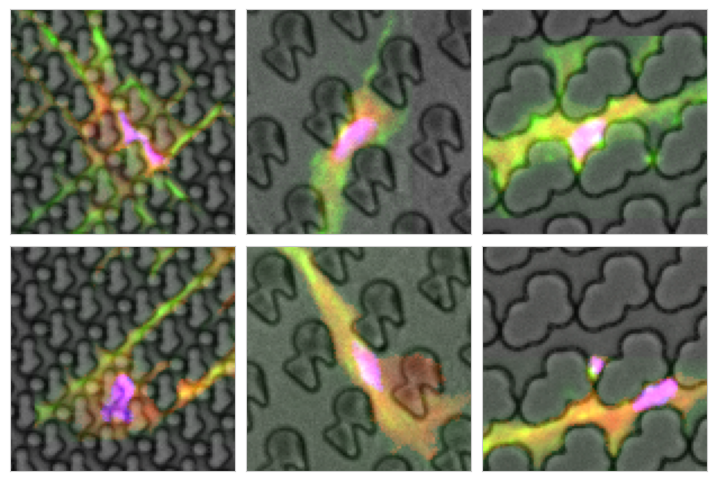

In [15]:
channel = None
show_labs = False
pixels = 100

js = [4,5,8]

def find_center(img, channel=-1):
    # find the max intensity pixerl for the specified channel to determine the center
    i_flat = np.argmax(img[...,channel])
    i = np.unravel_index(i_flat, shape=img[...,channel].shape)
    return i

def zoom_image(img, center, pixels):
    assert len(img.shape) == 3
    low, high = center[0] - pixels//2, center[0] + pixels//2
    low = min(max(0, low), img.shape[0] - pixels)
    high = max(min(img.shape[0], high), pixels)
    left, right = center[1] - pixels//2, center[1] + pixels//2
    left = min(max(0, left), img.shape[0] - pixels)
    right = max(min(img.shape[0], right), pixels)
    img = img[low:high, left:right]
    return img, (low, high, left, right)

fig, axs = plt.subplots(2, len(js), figsize=(3*len(js),3*2), gridspec_kw={'wspace': 0.05, 'hspace': 0.05})


spath = 'qualitative_images/'
if not os.path.exists(spath):
    os.makedirs(spath)
    
for i, source in enumerate(['real', 'fake']):
    for j_temp in range(len(js)):
        a  = axs[i, j_temp]
        j = js[j_temp]
        if source == 'real':
            img_and_bg = imgs_real[j, :]
        else:
            img_and_bg = imgs_gen[j, :]
            # bg = imgs[j, 0]
        # plot superimposed cell on bg:
        bg_norm = 0.0 if channel is not None else 0.5
        im_to_plot =  plot_topo_cells(img_and_bg.cpu().permute(1, 2, 0).numpy(), bg_norm=bg_norm) / 255.
        # zoom:
        center = find_center(im_to_plot, channel=-1)  # always base on dapi center so that loc stays consistent
        im_to_plot, _ = zoom_image(im_to_plot, center, pixels)
        mask = np.zeros_like(im_to_plot)
        if channel is not None:
            mask[..., channel] = 1
        else:
            mask = 1.
        a.imshow(im_to_plot * mask)
        # a.imshow(img.permute(1, 2, 0).cpu().detach().numpy())
        a.set_xticks([])
        a.set_yticks([])


labs = ('Real', 'Generated') if show_labs else ('\n', '\n')
axs[0,0].set_ylabel(labs[0], fontsize=16)
axs[1,0].set_ylabel(labs[1],fontsize=16)


plt.tight_layout(w_pad=1.08, h_pad=3.08)
plt.savefig(spath + f'qualitative_real_fake_zoom_chan{channel}.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

C:\Users\s161975\AppData\Local\Temp\ipykernel_7008\2992911627.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(w_pad=1.08, h_pad=3.08)


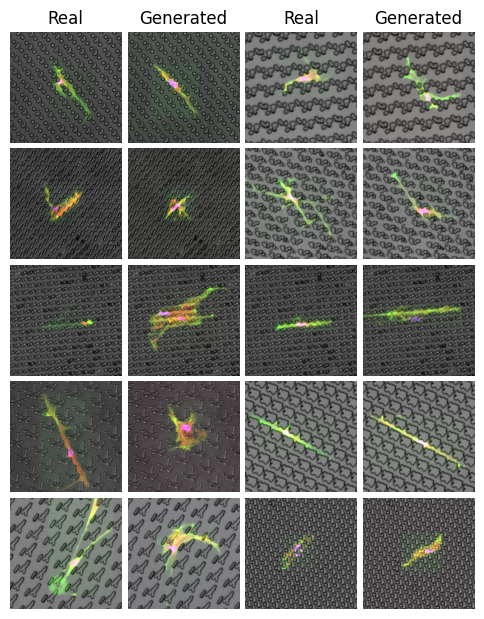

In [42]:
# 2 vertical stacks of qualitative images:
js = [0,1,10,3,4,5,12,7,8,11] #np.random.choice(range(k), k_to_plot, replace=False)

fig, axs = plt.subplots(len(js) // 2, 4, figsize=(6,1.5*len(js)/2), gridspec_kw={'wspace': 0.05, 'hspace': 0.05})


spath = 'qualitative_images/'
if not os.path.exists(spath):
    os.makedirs(spath)
    
for i, source in enumerate(['Real', 'Generated']*2):
    for j_temp in range(len(js)):
        a  = axs.T[i, int(j_temp % (len(js) / 2))]
        if j_temp == 0:
            a.set_title(source)
        j = js[int(j_temp % (len(js) / 2) + i//2 * (len(js) / 2))]
        if source == 'Real':
            img_and_bg = imgs_real[j, :]
        else:
            img_and_bg = imgs_gen[j, :]
            # bg = imgs[j, 0]
        # plot superimposed cell on bg:
        im_to_plot =  plot_topo_cells(img_and_bg.cpu().permute(1, 2, 0).numpy(), bg_norm=0.6) / 255.
        a.imshow(im_to_plot)
        # a.imshow(img.permute(1, 2, 0).cpu().detach().numpy())
        a.axis('off')


plt.tight_layout(w_pad=1.08, h_pad=3.08)
plt.savefig(spath + 'qualitative_real_fake_vertical.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [16]:
# save some samples of generative process:


k = 4
bs = 2

trajs_gen = []
bgs_traj = []
for i in tqdm(range(np.ceil(k/bs).astype(int))):
    random_idx = np.random.randint(all_bgs.shape[0], size=bs)
    bg = all_bgs[random_idx].to(device)
    x1 = all_imgs[random_idx].to(device)
    bgs_traj.append(bg.cpu())
    some_bgs = utils.prepare_cfg_conditioning(bg, 0) if use_cfg else bg
    trajs_this_gen = generate_samples_topo(model, None, 0, 'test', some_bgs[:, None, ...],
                                           num_int_steps=100, use_cfg=True, cfg_strength=1, x1=x1,
                                           return_whole_traj=True)
    trajs_gen.append(trajs_this_gen.cpu().permute(1,0,2,3,4))


trajs_gen = torch.cat(trajs_gen, dim=0)
bgs_traj = torch.cat(bgs_traj, dim=0)


  0%|          | 0/2 [00:00<?, ?it/s]

Your vector field does not have `nn.Parameters` to optimize.


 50%|█████     | 1/2 [00:17<00:17, 17.75s/it]

Your vector field does not have `nn.Parameters` to optimize.


100%|██████████| 2/2 [00:36<00:00, 18.13s/it]


100%|██████████| 3/3 [00:00<00:00, 14.97it/s]
C:\Users\s161975\AppData\Local\Temp\ipykernel_9428\3654518370.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


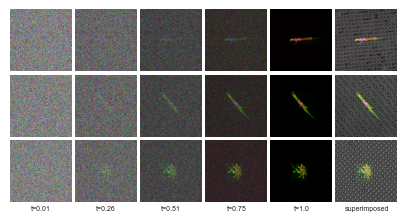

In [17]:
is_to_plot = [1, 2, 3]
num_times_to_plot = 5
steps_to_plot = np.round(np.linspace(0, trajs_gen.shape[1]-1, num_times_to_plot)).astype(int)

fig, ax = plt.subplots(len(is_to_plot), len(steps_to_plot)+1, figsize=((len(steps_to_plot)),2.5),
                       gridspec_kw={'wspace': 0.05, 'hspace': 0.05})

for i1, i_to_plot in tqdm(enumerate(is_to_plot), total=len(is_to_plot)):
    for i2, t in enumerate(steps_to_plot):
        im_to_plot =  plot_topo_cells(trajs_gen[i_to_plot, t].permute(1,2,0).numpy(), bg_norm=0.4) / 255.
        ax[i1, i2].imshow(im_to_plot)
        ax[i1, i2].axis('off')

    ax[i1, -1].imshow(plot_topo_cells(
        torch.cat([
            bgs_traj[i_to_plot],
            trajs_gen[i_to_plot, -1]], dim=0
            ).cpu().permute(1,2,0).numpy(),
                bg_norm=0.6
        ) / 255.)
    ax[i1, -1].axis('off')

# add below the last line of subplots the corresponding timestamps (steps_to_plot+1) and for the final column the word 'superimposed':

for i2, t in enumerate(steps_to_plot):
    ax[-1, i2].text(0.5, -0.1, f't={float(np.round((t+1)/100,2))}', fontsize=5, ha='center', va='center', transform=ax[-1, i2].transAxes)
    ax[-1, i2].axis('off')

ax[-1, -1].text(0.5, -0.1, 'superimposed', fontsize=5, ha='center', va='center', transform=ax[-1, -1].transAxes)

plt.tight_layout()
plt.savefig(spath + 'qualitative_traj.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [21]:
all_bgs[bg_id].permute(1,2,0).shape

torch.Size([300, 300, 1])

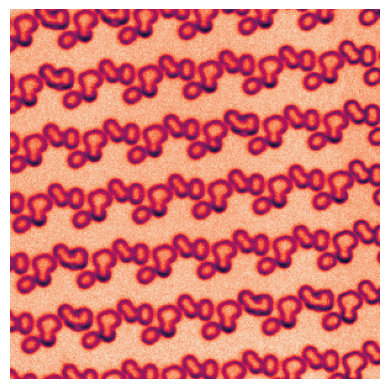

  0%|          | 0/6 [00:00<?, ?it/s]

Your vector field does not have `nn.Parameters` to optimize.


In [ ]:
# classifier-free guidance diversity-fidelity trade-off:



k = 4
bg_id = 5
plt.imshow(all_bgs[bg_id].permute(1,2,0).cpu().numpy())
plt.axis('off')
plt.show()
cfg_strengths = [0, 0.1, 0.25, 0.5, 0.9, 1.]

imgs_gen_cfg = []
bgs = all_bgs[bg_id:bg_id+1].to(device).repeat(k, 1, 1, 1)
x1 = all_imgs[bg_id:bg_id+1].to(device).repeat(k, 1, 1, 1)

for cfg_strength in tqdm(cfg_strengths):
    bg = bgs
    some_bgs = utils.prepare_cfg_conditioning(bg, 0) if use_cfg else bg
    imgs_this_gen = generate_samples_topo(model, None, 0, 'test', some_bgs[:, None, ...], num_int_steps=100, use_cfg=True,
                                            cfg_strength=cfg_strength, x1=x1)
    imgs_gen_cfg.append(imgs_this_gen.cpu())



In [ ]:
# make the plot:


fig, axs = plt.subplots(k, len(cfg_strengths),figsize=(len(cfg_strengths), k), gridspec_kw={'wspace': 0.05, 'hspace': 0.05})

for i in range(k):
    for j in range(len(cfg_strengths)):
        a = axs[i, j]
        img_and_bg = imgs_gen_cfg[j][i]
        im_to_plot = plot_topo_cells(img_and_bg.permute(1,2,0).numpy(), bg_norm=0.6) / 255.
        a.imshow(im_to_plot)
        a.axis('off')

# add cfg strength labels below the last row:

for j in range(len(cfg_strengths)):
    axs[-1, j].text(0.5, -0.1, f'$w$={cfg_strengths[j]}', fontsize=10, ha='center', va='center', transform=axs[-1, j].transAxes)
    axs[-1, j].axis('off')

plt.tight_layout()
# plt.savefig(spath + f'qualitative_cfg_bg{bg_id}.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()